In [1]:
# Cell 1: Import libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import joblib
from pathlib import Path

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# Find the existing project dataset

possible_paths = [
    Path("../data/customer-churn-training.csv"),
    Path("data/customer-churn-training.csv"),
    Path("../../data/customer-churn-training.csv")
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "customer-churn-training.csv not found. "
        "Check that the notebook is inside 03_Preprocessing "
        "and the CSV is inside the project's data folder."
    )

df = pd.read_csv(data_path)

# Clean whitespace in column names and text values
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset loaded from:", data_path.resolve())
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded from: D:\INTERNSHIP WORK\RabTech-AI-ML-Internship\data\customer-churn-training.csv
Dataset shape: (12, 7)


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique customer IDs:", df["customer_id"].nunique())

print("\nChurn target distribution:")
display(df["churned"].value_counts().sort_index())

print("\nTarget meaning:")
print("0 = Customer did not churn")
print("1 = Customer churned")

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        12 non-null     object
 1   tenure_months      12 non-null     int64 
 2   support_tickets    12 non-null     int64 
 3   monthly_spend_inr  12 non-null     int64 
 4   last_login_days    12 non-null     int64 
 5   plan_type          12 non-null     object
 6   churned            12 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 804.0+ bytes

Missing values:


,missing_count
customer_id,0
tenure_months,0
support_tickets,0
monthly_spend_inr,0
last_login_days,0
plan_type,0
churned,0



Duplicate rows: 0

Unique customer IDs: 12

Churn target distribution:


churned
0    7
1    5
Name: count, dtype: int64


Target meaning:
0 = Customer did not churn
1 = Customer churned


,tenure_months,support_tickets,monthly_spend_inr,last_login_days
tenure_months,1.00,-0.89,0.87,-0.83
support_tickets,-0.89,1.00,-0.79,0.94
monthly_spend_inr,0.87,-0.79,1.00,-0.82
last_login_days,-0.83,0.94,-0.82,1.00


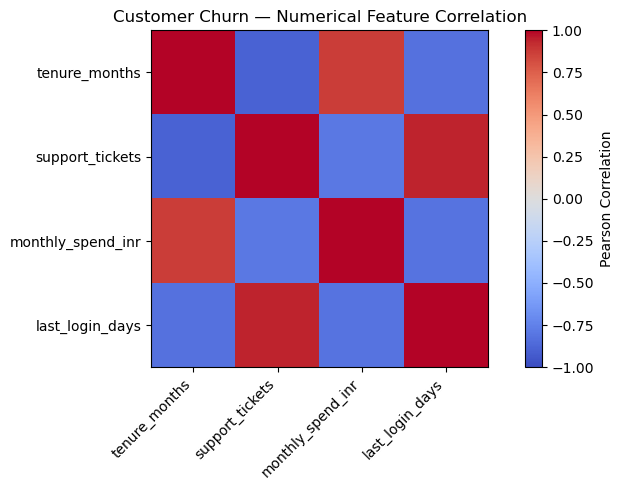

In [6]:
numeric_columns = [
    "tenure_months",
    "support_tickets",
    "monthly_spend_inr",
    "last_login_days"
]

correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(8, 5))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")
plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(numeric_columns)), numeric_columns)

plt.title("Customer Churn — Numerical Feature Correlation")
plt.tight_layout()
plt.show()

In [7]:
target_column = "churned"

X = df.drop(columns=["customer_id", target_column])
y = df[target_column].astype(int)

print("Input features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

assert set(y.unique()).issubset({0, 1}), (
    "Target must contain only 0 and 1."
)

Input features:
['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type']

X shape: (12, 5)
y shape: (12,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts().sort_index())

Training records: 9
Testing records: 3

Training target distribution:


churned
0    5
1    4
Name: count, dtype: int64


Testing target distribution:


churned
0    2
1    1
Name: count, dtype: int64

In [9]:
numeric_features = [
    "tenure_months",
    "support_tickets",
    "monthly_spend_inr",
    "last_login_days"
]

categorical_features = ["plan_type"]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']
Categorical features: ['plan_type']


In [10]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Numerical pipeline created.")
print("Categorical pipeline created.")

Numerical pipeline created.
Categorical pipeline created.


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("ColumnTransformer created successfully.")

ColumnTransformer created successfully.


In [12]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

model_pipeline.fit(X_train, y_train)

print("Pipeline training completed.")

Pipeline training completed.


In [13]:
y_pred = model_pipeline.predict(X_test)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(metrics.round(4))

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not Churned", "Churned"],
    zero_division=0
))

,Metric,Score
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1 Score,1.0


              precision    recall  f1-score   support

 Not Churned       1.00      1.00      1.00         2
     Churned       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



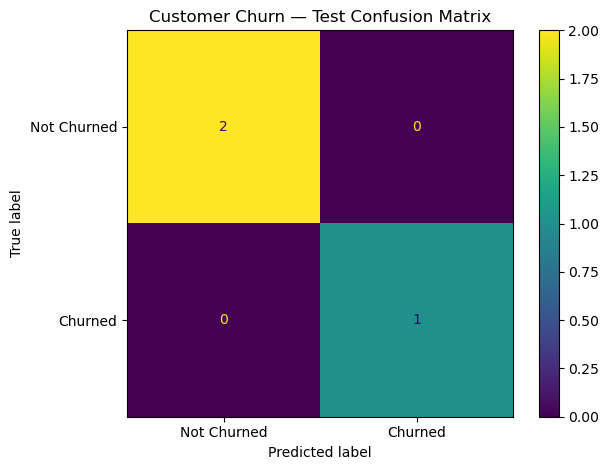

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
).plot(values_format="d")

plt.title("Customer Churn — Test Confusion Matrix")
plt.tight_layout()
plt.show()

,feature,importance
0,numeric__support_tickets,0.263534
1,numeric__tenure_months,0.259249
2,numeric__monthly_spend_inr,0.183421
3,categorical__plan_type_Basic,0.150000
4,numeric__last_login_days,0.106212
5,categorical__plan_type_Pro,0.031118
6,categorical__plan_type_Standard,0.006466


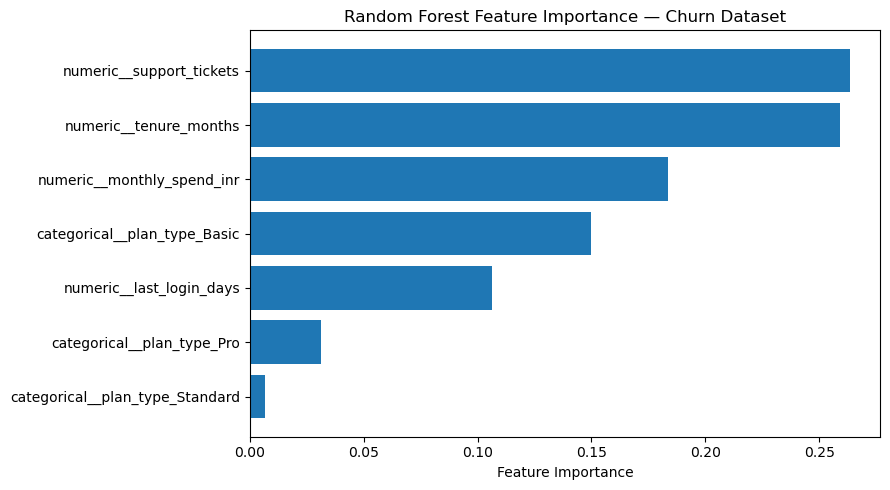

In [15]:
fitted_preprocessor = model_pipeline.named_steps["preprocessor"]
fitted_model = model_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": fitted_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance — Churn Dataset")
plt.tight_layout()
plt.show()

In [16]:
# Resolve project root from the notebook's working directory
cwd = Path.cwd()

if cwd.name == "03_Preprocessing":
    project_root = cwd.parent
elif (cwd / "data" / "customer-churn-training.csv").exists():
    project_root = cwd
else:
    project_root = cwd.parent

models_dir = project_root / "models"
reports_dir = project_root / "reports"

models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model_pipeline,
    models_dir / "customer_churn_preprocessing_pipeline.joblib"
)

metrics.to_csv(
    reports_dir / "task03_model_metrics.csv",
    index=False
)

importance_df.to_csv(
    reports_dir / "task03_feature_importance.csv",
    index=False
)

correlation_matrix.to_csv(
    reports_dir / "task03_correlation_matrix.csv"
)

print("Model and reports saved successfully.")
print("Models folder:", models_dir.resolve())
print("Reports folder:", reports_dir.resolve())

Model and reports saved successfully.
Models folder: D:\INTERNSHIP WORK\RabTech-AI-ML-Internship\models
Reports folder: D:\INTERNSHIP WORK\RabTech-AI-ML-Internship\reports


In [17]:
loaded_pipeline = joblib.load(
    models_dir / "customer_churn_preprocessing_pipeline.joblib"
)

sample = X_test.head(2)
sample_predictions = loaded_pipeline.predict(sample)

verification = sample.copy()
verification["actual_churned"] = y_test.loc[sample.index]
verification["predicted_churned"] = sample_predictions

display(verification)

print("\nTask 03 pipeline verification completed.")
print("Important limitation: only 12 records are available.")
print("Do not claim production readiness from this small dataset.")

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,actual_churned,predicted_churned
9,4,3,499,12,Basic,1,1
11,7,2,799,9,Standard,0,0



Task 03 pipeline verification completed.
Important limitation: only 12 records are available.
Do not claim production readiness from this small dataset.
